Q-table (rows = states, cols = Up, Down, Left, Right):
      Up  Down  Left  Right
0  -0.26  1.81  0.04  -2.12
1  -1.65 -2.71 -1.63  -0.73
2  -0.93  1.60 -1.18  -0.95
3  -0.77 -0.80 -0.85  -0.77
4  -0.04  3.12  0.85  -7.71
5   0.00  0.00  0.00   0.00
6  -0.54  4.76 -1.00  -0.49
7  -0.63 -1.00 -0.65  -0.59
8   1.00  0.88  1.56   4.58
9  -7.71  6.20  1.86   3.57
10  0.15  7.94 -0.30  -4.10
11  0.00  0.00  0.00   0.00
12  0.02 -0.20 -0.08   5.13
13  3.34  5.28  1.44   8.00
14  4.69  5.97  4.86  10.00
15  0.00  0.00  0.00   0.00

Optimal (greedy) policy:
 ↓ → ↓ ↑
 ↓ P ↓ →
 → ↓ ↓ P
 → → → G

Strategy Avg Reward Success % Avg reward (last 100)
High (eps=0.5)        -6.34   57.30    -5.51
Balanced (eps=0.1)     2.47   91.82     3.43
Low (eps=0.01)         3.96   97.62     4.86


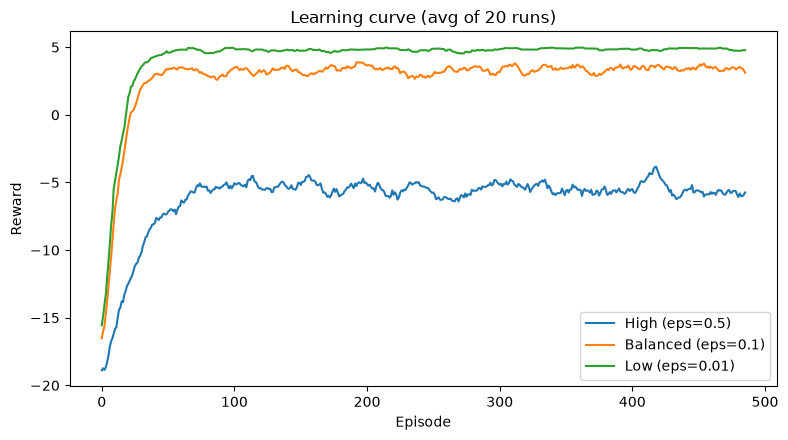

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 4x4 Grid World: start (0,0), goal (3,3) = +10, pits (1,1),(2,3) = -10, each step = -1
N, START, GOAL, PITS = 4, (0, 0), (3, 3), {(1, 1), (2, 3)}
MOVES = [(-1, 0), (1, 0), (0, -1), (0, 1)] # Up, Down, Left, Right
ARROWS = ["↑", "↓", "←", "→"]

def step(pos, a):
    r, c = pos[0] + MOVES[a][0], pos[1] + MOVES[a][1]
    if not (0 <= r < N and 0 <= c < N): 
        r, c = pos # invalid move > stay
    if (r, c) == GOAL: 
        return (r, c), 10, True
    if (r, c) in PITS: 
        return (r, c), -10, True
    return (r, c), -1, False

def q_learning(episodes=500, alpha=0.1, gamma=0.9, eps=0.1, seed=0):
    rng = np.random.default_rng(seed)
    Q = np.zeros((N * N, 4))
    rewards, success = [], []
    for ep in range(episodes):
        pos, total, done = START, 0, False
        for t in range(100):
            s = pos[0] * N + pos[1]
            a = rng.integers(4) if rng.random() < eps else rng.choice(np.flatnonzero(Q[s] == Q[s].max()))
            pos, r, done = step(pos, a)
            s2 = pos[0] * N + pos[1]
            Q[s, a] += alpha * (r + (0 if done else gamma * Q[s2].max()) - Q[s, a]) # Q-learning update
            total += r
            if done: 
                break
        rewards.append(total)
        success.append(pos == GOAL)
    return Q, np.array(rewards), np.array(success)

Q, rewards, success = q_learning(eps=0.1)
print("Q-table (rows = states, cols = Up, Down, Left, Right):")
print(pd.DataFrame(Q, columns=["Up", "Down", "Left", "Right"]).round(2).to_string())

policy = Q.argmax(axis=1)
print("\nOptimal (greedy) policy:")
for r in range(N):
    print(" " + " ".join("G" if (r, c) == GOAL else "P" if (r, c) in PITS else ARROWS[policy[r * N + c]] for c in range(N)))

print("\nStrategy Avg Reward Success % Avg reward (last 100)")
curves = {}
for name, e in [("High (eps=0.5)", 0.5), ("Balanced (eps=0.1)", 0.1), ("Low (eps=0.01)", 0.01)]:
    runs = [q_learning(eps=e, seed=s) for s in range(20)]
    R = np.array([r for _, r, _ in runs])
    S = np.array([s for _, _, s in runs])
    curves[name] = R.mean(axis=0)
    print("%-18s %8.2f %7.2f %8.2f" % (name, R.mean(), S.mean() * 100, R[:, -100:].mean()))

fig, ax = plt.subplots(figsize=(8, 4.5))
for name, c in curves.items():
    ax.plot(np.convolve(c, np.ones(15) / 15, mode="valid"), label=name)
ax.set_xlabel("Episode")
ax.set_ylabel("Reward")
ax.set_title("Learning curve (avg of 20 runs)")
ax.legend()
plt.tight_layout()